# Lucrarea 3 — Train/Test Split, codificare și regresie liniară
## Student : Trandafir Florin-Daniel, IASD2601
Rezolvarea exercițiilor 1–6 din `03_Train_Test_Splits_Validation_Linear_Regression.ipynb`, pe datele Ames Housing. Toate celulele se pot rula în ordine, din directorul acestui notebook.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler, StandardScaler

CSV_PATH = Path("Ames_Housing_Sales - Ames_Housing_Sales.csv")
TARGET = "SalePrice"


## Exercițiul 1 — Importul și tipurile datelor

Citirea implicită din Pandas interpretează textul `None` ca valoare lipsă. În acest fișier, `None` este o categorie (de exemplu, absența garajului sau a gardului), așa că folosim `keep_default_na=False`.


In [2]:
data = pd.read_csv(CSV_PATH, keep_default_na=False)
print("Dimensiune (rânduri, coloane):", data.shape)
print("Tipuri de date:")
print(data.dtypes.astype(str).value_counts().to_string())
print("Valori lipsă:", int(data.isna().sum().sum()))
assert data.shape == (1379, 80)
assert TARGET in data.columns


Dimensiune (rânduri, coloane): (1379, 80)
Tipuri de date:
str        43
int64      36
float64     1
Valori lipsă: 0


Datele au **79 de caracteristici** și predictorul `SalePrice`. În versiunea curentă de Pandas, coloanele text pot apărea cu tipul `str`/`string`, în loc de `object`; acestea reprezintă aceleași caracteristici categoriale.


## Exercițiul 2 — Câte caracteristici produce codificarea one-hot?

Pentru o coloană cu `n` categorii folosim `n − 1` coloane indicator și eliminăm coloana text inițială. Astfel păstrăm o categorie de referință și evităm dependența liniară completă dintre indicatori.


In [3]:
categorical_cols = data.select_dtypes(exclude="number").columns.tolist()
category_counts = data[categorical_cols].nunique(dropna=False)
new_indicator_count = int((category_counts - 1).sum())
feature_count_after = (data.shape[1] - 1) - len(categorical_cols) + new_indicator_count

print("Coloane categoriale:", len(categorical_cols))
print("Coloane indicator (n - 1 pentru fiecare):", new_indicator_count)
print("Caracteristici inițiale:", data.shape[1] - 1)
print("Caracteristici după codificare:", feature_count_after)
print("Creștere netă:", feature_count_after - (data.shape[1] - 1))


Coloane categoriale: 43
Coloane indicator (n - 1 pentru fiecare): 215
Caracteristici inițiale: 79
Caracteristici după codificare: 251
Creștere netă: 172


Rezultă **251 de caracteristici** după codificare, față de 79 inițial: o creștere netă de 172. `DictVectorizer` ar fi util când observațiile sunt deja reprezentate ca dicționare cu atribute variabile; aici coloanele din DataFrame pot fi codificate direct.


## Exercițiul 3 — Cele două variante ale datelor

Construim o variantă numai cu caracteristici numerice și una cu indicatori one-hot pentru toate coloanele categoriale. `drop_first=True` aplică regula `n − 1` din exercițiul anterior.


In [4]:
data_numeric = data.drop(columns=categorical_cols).copy()
data_one_hot = pd.get_dummies(
    data, columns=categorical_cols, drop_first=True, dtype=float
)
print("Fără coloane categoriale:", data_numeric.shape)
print("Cu one-hot:", data_one_hot.shape)
print("Diferență față de datele inițiale:", data_one_hot.shape[1] - data.shape[1])
assert data_numeric.shape == (1379, 37)
assert data_one_hot.shape == (1379, 252)
assert not data_one_hot.isna().any().any()


Fără coloane categoriale: (1379, 37)
Cu one-hot: (1379, 252)
Diferență față de datele inițiale: 172


Varianta numerică are **36 de caracteristici** și predictorul. Varianta one-hot are **251 de caracteristici** și predictorul. Nu codificăm numeric prin `LabelEncoder` deoarece `get_dummies` lucrează direct cu etichetele text, fără să inventeze o ordine între categorii.


## Exercițiul 4 — Împărțire și regresie liniară

Pentru ambele variante folosim 70% din observații la antrenare și 30% la testare, cu aceeași sămânță aleatoare. Comparăm MSE pe ambele părți.


In [5]:
X_numeric = data_numeric.drop(columns=TARGET)
y_numeric = data_numeric[TARGET]
X_one_hot = data_one_hot.drop(columns=TARGET)
y_one_hot = data_one_hot[TARGET]

X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(
    X_numeric, y_numeric, test_size=0.30, random_state=42
)
X_train_hot, X_test_hot, y_train_hot, y_test_hot = train_test_split(
    X_one_hot, y_one_hot, test_size=0.30, random_state=42
)
assert X_train_num.index.equals(X_train_hot.index)
assert X_test_num.index.equals(X_test_hot.index)
assert y_train_num.equals(y_train_hot)
assert y_test_num.equals(y_test_hot)

model_num = LinearRegression().fit(X_train_num, y_train_num)
model_hot = LinearRegression().fit(X_train_hot, y_train_hot)
pred_train_num = model_num.predict(X_train_num)
pred_test_num = model_num.predict(X_test_num)
pred_train_hot = model_hot.predict(X_train_hot)
pred_test_hot = model_hot.predict(X_test_hot)

errors_basic = pd.DataFrame(
    {
        "MSE antrenare": [
            mean_squared_error(y_train_num, pred_train_num),
            mean_squared_error(y_train_hot, pred_train_hot),
        ],
        "MSE testare": [
            mean_squared_error(y_test_num, pred_test_num),
            mean_squared_error(y_test_hot, pred_test_hot),
        ],
    },
    index=["Fără categorice", "One-hot"],
)
print("Aceleași observații în ambele împărțiri: da")
print("Rânduri antrenare/testare:", len(X_train_num), "/", len(X_test_num))
print(errors_basic.round(2).to_string())


Aceleași observații în ambele împărțiri: da
Rânduri antrenare/testare: 965 / 414
                 MSE antrenare   MSE testare
Fără categorice   1.131507e+09  1.372182e+09
One-hot           3.432227e+08  2.698477e+09


Pe aceste date, modelul fără coloane categoriale are MSE mai mic pe testare. Modelul one-hot obține o eroare mult mai mică la antrenare, dar mai mare la testare, ceea ce indică supraadaptare și instabilitate din cauza numărului mare de caracteristici față de numărul de observații. Valorile exacte pot varia ușor între versiuni ale bibliotecilor și implementări numerice.


## Exercițiul 5 — Asimetrie și scalare

Calculăm asimetria numai pe setul de antrenare. Multe caracteristici sunt puternic asimetrice, în special cele cu numeroase zerouri. O transformare `log1p` ar putea fi testată separat; aici păstrăm aceleași caracteristici pentru a izola efectul celor trei scalere cerute. Scalăm toate cele **36 de caracteristici numerice inițiale**, fără coloanele indicator one-hot și fără `SalePrice`.


In [6]:
numeric_feature_cols = X_numeric.columns.tolist()
skewness = X_train_num[numeric_feature_cols].skew()
most_skewed = skewness.abs().sort_values(ascending=False).head(10)
print("Cele mai asimetrice 10 caracteristici numerice (|skew|):")
print(most_skewed.round(2).to_string())
print("Număr cu |skew| > 1:", int((skewness.abs() > 1).sum()))


Cele mai asimetrice 10 caracteristici numerice (|skew|):
MiscVal          26.92
PoolArea         15.78
LotArea          11.50
LowQualFinSF     11.21
3SsnPorch        10.15
KitchenAbvGr      5.50
ScreenPorch       4.60
BsmtFinSF2        4.47
BsmtHalfBath      3.88
EnclosedPorch     3.22
Număr cu |skew| > 1: 19


In [7]:
scaler_types = {
    "StandardScaler": StandardScaler,
    "MinMaxScaler": MinMaxScaler,
    "MaxAbsScaler": MaxAbsScaler,
}
datasets = {
    "Fără categorice": (X_train_num, X_test_num, y_train_num, y_test_num),
    "One-hot": (X_train_hot, X_test_hot, y_train_hot, y_test_hot),
}
scaled_results = []
for dataset_name, (X_train, X_test, y_train, y_test) in datasets.items():
    for scaler_name, Scaler in scaler_types.items():
        scaler = Scaler()
        X_train_scaled = X_train.copy()
        X_test_scaled = X_test.copy()
        X_train_scaled[numeric_feature_cols] = scaler.fit_transform(
            X_train[numeric_feature_cols]
        )
        X_test_scaled[numeric_feature_cols] = scaler.transform(
            X_test[numeric_feature_cols]
        )
        model = LinearRegression().fit(X_train_scaled, y_train)
        scaled_results.append(
            {
                "Date": dataset_name,
                "Scaler": scaler_name,
                "MSE antrenare": mean_squared_error(
                    y_train, model.predict(X_train_scaled)
                ),
                "MSE testare": mean_squared_error(
                    y_test, model.predict(X_test_scaled)
                ),
            }
        )
errors_scaled = pd.DataFrame(scaled_results).set_index(["Date", "Scaler"])
print(errors_scaled.round(2).to_string())


                                MSE antrenare   MSE testare
Date            Scaler                                     
Fără categorice StandardScaler   1.131507e+09  1.372182e+09
                MinMaxScaler     1.131507e+09  1.372182e+09
                MaxAbsScaler     1.131507e+09  1.372182e+09
One-hot         StandardScaler   3.177267e+08  4.964292e+09
                MinMaxScaler     3.177267e+08  4.964292e+09
                MaxAbsScaler     3.177267e+08  4.964292e+09


Scalarea este ajustată **exclusiv pe antrenare** și aplicată apoi pe testare. În regresia liniară nepenalizată, o rescalare liniară a caracteristicilor nu ar trebui să schimbe substanțial predicțiile; aici cele trei metode au MSE aproape identic în cadrul fiecărei variante. Diferențele dintre rezultatele scalate și cele inițiale pentru varianta one-hot pot apărea din instabilitatea numerică a unei matrice cu multe coloane corelate.


## Exercițiul 6 — Predicții față de valorile reale

Reprezentăm modelul numeric de la exercițiul 4, care a obținut MSE mai mic pe setul de testare. Linia punctată arată predicția perfectă.


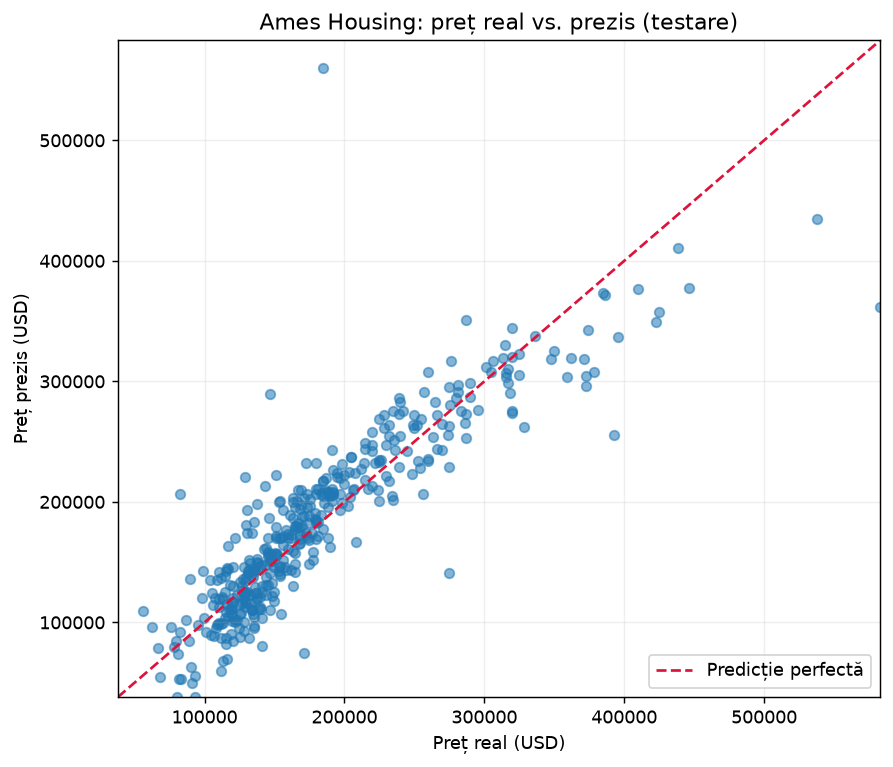

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test_num, pred_test_num, alpha=0.55, s=28)
limits = (
    min(y_test_num.min(), pred_test_num.min()),
    max(y_test_num.max(), pred_test_num.max()),
)
ax.plot(limits, limits, "--", color="crimson", label="Predicție perfectă")
ax.set(
    xlim=limits, ylim=limits,
    xlabel="Preț real (USD)", ylabel="Preț prezis (USD)",
    title="Ames Housing: preț real vs. prezis (testare)",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


Punctele apropiate de diagonală au predicții bune. Abaterile vizibile, mai ales pentru unele locuințe scumpe, arată că un model liniar simplu nu explică toate diferențele de preț.
